In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
t = 2.7  # eV
acc = 0.142  # nm (carbon-carbon distance)


N = 200
k_max = 4 * np.pi / (3 * np.sqrt(3) * acc)
kx = np.linspace(-k_max, k_max, N)
ky = np.linspace(-k_max, k_max, N)
KX, KY = np.meshgrid(kx, ky)

### Squate Lattice Dispersion
a_sq = 0.246  # Effective square lattice spacing
E_square = -2 * t * (np.cos(KX * a_sq) + np.cos(KY * a_sq))

### Honeycomb Dispersion
f = (
    1
    + 4 * np.cos(np.sqrt(3) * KY * acc / 2) * np.cos(3 * KX * acc / 2)
    + 4 * np.cos(3 * KY * acc / 2) ** 2
)
E_honeycomb_pos = t * np.sqrt(3 + f)
E_honeycomb_neg = -t * np.sqrt(3 + f)

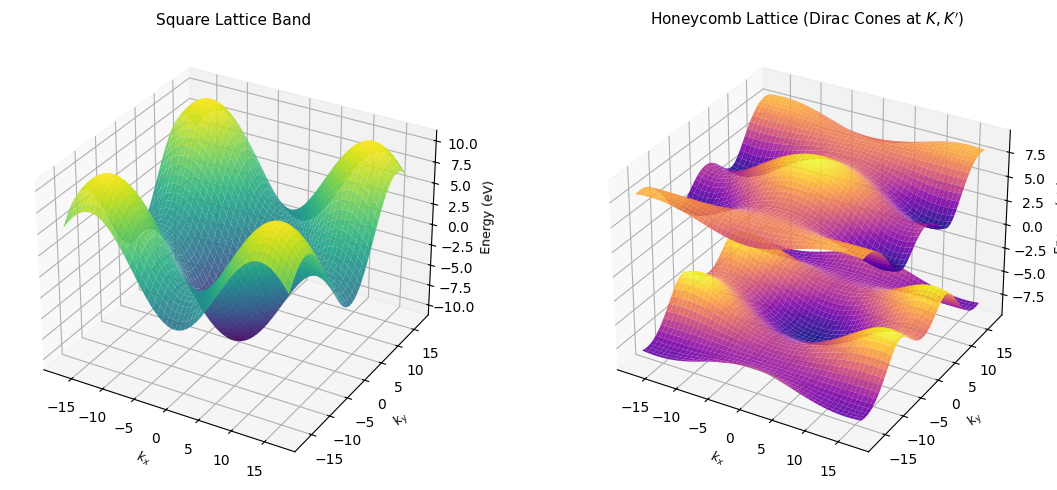

In [3]:
fig = plt.figure(figsize=(12, 5))

# Square Lattice Plot
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(KX, KY, E_square, cmap='viridis', edgecolor='none', alpha=0.9)
ax1.set_title('Square Lattice Band', fontsize=11)
ax1.set_xlabel('$k_x$', fontsize=9)
ax1.set_ylabel('$k_y$', fontsize=9)
ax1.set_zlabel('Energy (eV)', fontsize=9)

# Honeycomb Lattice Plot (Conduction & Valence Bands)
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(
    KX, KY, E_honeycomb_pos, cmap='plasma', edgecolor='none', alpha=0.9
)
ax2.plot_surface(
    KX, KY, E_honeycomb_neg, cmap='plasma', edgecolor='none', alpha=0.9
)
ax2.set_title(
    'Honeycomb Lattice (Dirac Cones at $K, K^{\\prime}$)', fontsize=11
)
ax2.set_xlabel('$k_x$', fontsize=9)
ax2.set_ylabel('$k_y$', fontsize=9)
ax2.set_zlabel('Energy (eV)', fontsize=9)

plt.tight_layout()
plt.show()

In [42]:
# Parameters
t = 1.0  # Hopping parameter (eV)
eta = 0.05  # Lorentzian broadening factor
hbar = 1
m_star = 1
E_grid1 = np.linspace(-6.2, 6.2, 400)
#E_grid = np.linspace(0.005, 3.0, 400)
# --- 1. 1D Chain DOS ---
N_1d = 5000
k_1d = np.linspace(-np.pi, np.pi, N_1d)
E_1d = -2 * t * np.cos(k_1d)

dos_1d_num = np.zeros_like(E_grid)
for e in E_1d:
  dos_1d_num += (1 / np.pi) * (eta / ((E_grid - e) ** 2 + eta**2))
dos_1d_num /= N_1d

dos_1d_theory = (1 / (np.pi * hbar)) * np.sqrt(2 * m_star / E_grid)

In [43]:
#-----2. 2D chain DOS -----
N_2d = 300
kx_2d = np.linspace(-np.pi, np.pi, N_2d)
ky_2d = np.linspace(-np.pi, np.pi, N_2d)
KX, KY = np.meshgrid(kx_2d, ky_2d)

E_2d = -2 * t * (np.cos(KX) + np.cos(KY))
E_2d_flat = E_2d.flatten()

dos_2d_num = np.zeros_like(E_grid)
for e in E_2d_flat:
  dos_2d_num += (1 / np.pi) * (eta / ((E_grid - e) ** 2 + eta**2))
dos_2d_num /= len(E_2d_flat)

dos_2d_theory = np.full_like(E_grid, (m_star / (np.pi * hbar**2)) / t)

In [44]:
# --- 3. 3D Simple Cubic Lattice DOS ---
N_3d = 60
kx_3d = np.linspace(-np.pi, np.pi, N_3d)
ky_3d = np.linspace(-np.pi, np.pi, N_3d)
kz_3d = np.linspace(-np.pi, np.pi, N_3d)
K_X, K_Y, K_Z = np.meshgrid(kx_3d, ky_3d, kz_3d, indexing='ij')
E_3d = -2 * t * (np.cos(K_X) + np.cos(K_Y) + np.cos(K_Z))
E_3d_flat = E_3d.flatten()

dos_3d_num = np.zeros_like(E_grid)
for e in E_3d_flat:
  dos_3d_num += (1 / np.pi) * (eta / ((E_grid - e) ** 2 + eta**2))
dos_3d_num /= len(E_3d_flat)

dos_3d_theory = ( (1 / (2 * np.pi**2)) * ((2 * m_star / hbar**2) ** 1.5) * np.sqrt(E_grid))

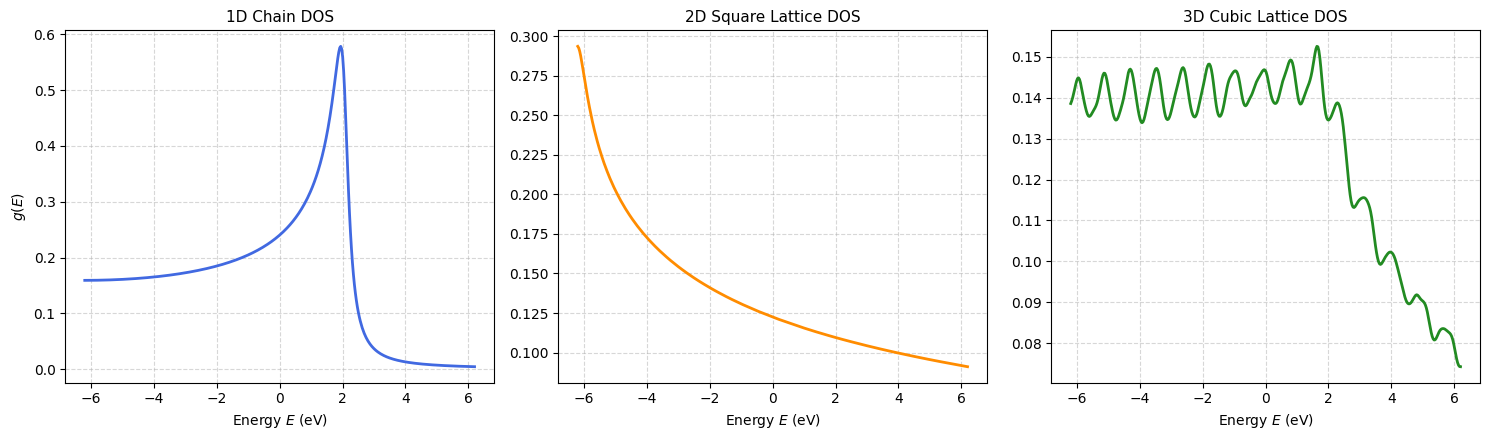

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1D Plot
axes[0].plot(E_grid1, dos_1d_num, color='royalblue', linewidth=2)
axes[0].set_title('1D Chain DOS', fontsize=11)
axes[0].set_xlabel('Energy $E$ (eV)', fontsize=10)
axes[0].set_ylabel('$g(E)$', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2D Plot
axes[1].plot(E_grid1, dos_2d_num, color='darkorange', linewidth=2)
axes[1].set_title('2D Square Lattice DOS', fontsize=11)
axes[1].set_xlabel('Energy $E$ (eV)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3D Plot
axes[2].plot(E_grid1, dos_3d_num, color='forestgreen', linewidth=2)
axes[2].set_title('3D Cubic Lattice DOS', fontsize=11)
axes[2].set_xlabel('Energy $E$ (eV)', fontsize=10)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

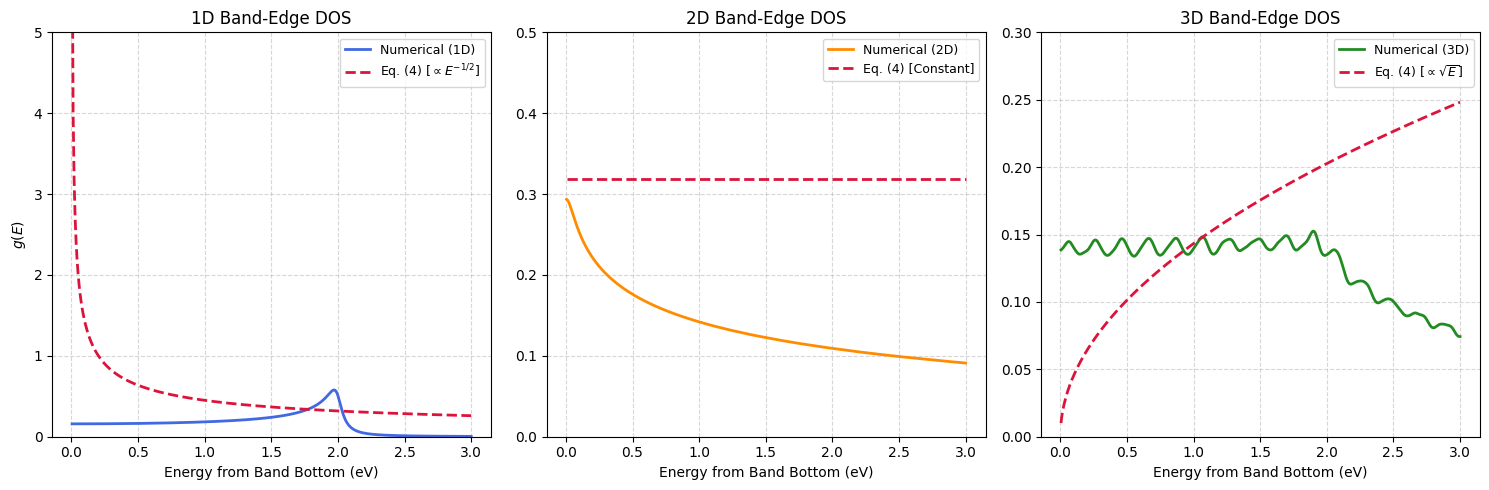

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1D Comparison
axes[0].plot(E_grid,dos_1d_num,color='royalblue',linewidth=2, label='Numerical (1D)',)
axes[0].plot( E_grid, dos_1d_theory,color='crimson',linestyle='--',linewidth=2,label='Eq. (4) [$\\propto E^{-1/2}$]',)
axes[0].set_title('1D Band-Edge DOS', fontsize=12)
axes[0].set_xlabel('Energy from Band Bottom (eV)', fontsize=10)
axes[0].set_ylabel('$g(E)$', fontsize=10)
axes[0].set_ylim(0, 5)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=9)

# 2D Comparison
axes[1].plot(E_grid,  dos_2d_num,color='darkorange',linewidth=2,  label='Numerical (2D)',)
axes[1].plot(E_grid,dos_2d_theory,color='crimson',linestyle='--',linewidth=2,label='Eq. (4) [Constant]',)
axes[1].set_title('2D Band-Edge DOS', fontsize=12)
axes[1].set_xlabel('Energy from Band Bottom (eV)', fontsize=10)
axes[1].set_ylim(0, 0.5)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=9)

# 3D Comparison
axes[2].plot(E_grid,dos_3d_num,color='forestgreen',linewidth=2,label='Numerical (3D)',)
axes[2].plot(E_grid,dos_3d_theory,color='crimson',linestyle='--',linewidth=2,label='Eq. (4) [$\\propto \\sqrt{E}$]',)
axes[2].set_title('3D Band-Edge DOS', fontsize=12)
axes[2].set_xlabel('Energy from Band Bottom (eV)', fontsize=10)
axes[2].set_ylim(0, 0.3)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

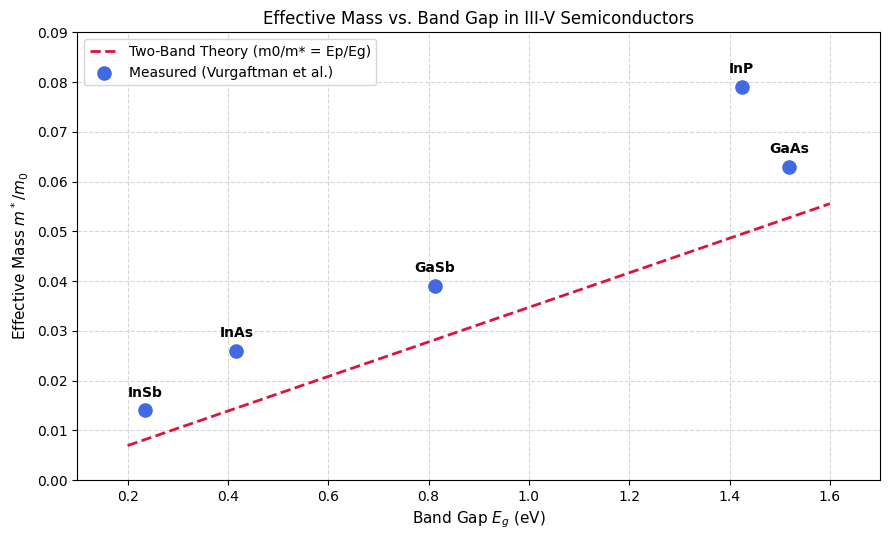

In [47]:

# III-V Semiconductor Data (Vurgaftman et al. 0K values)
materials = ['InSb', 'InAs', 'GaSb', 'InP', 'GaAs']
Eg = np.array([0.235, 0.417, 0.812, 1.424, 1.519])  # Band gap in eV
m_star_measured = np.array([0.014, 0.026, 0.039, 0.079, 0.063])  # Measured m*/m0

# Theoretical Curve: m0 / m* = Ep / Eg (Assuming Ep = 28.8 eV)
Ep = 28.8
Eg_fine = np.linspace(0.2, 1.6, 100)
m_star_theory = 1 / (Ep / Eg_fine)

# Plotting
plt.figure(figsize=(9, 5.5))

# Theoretical Trend Line
plt.plot(Eg_fine,m_star_theory,color='crimson',linestyle='--',linewidth=2,label='Two-Band Theory (m0/m* = Ep/Eg)',)

# Measured Data Points
plt.scatter(Eg,m_star_measured, color='royalblue', s=90, zorder=5, label='Measured (Vurgaftman et al.)',)

# Annotate each material point
for i, mat in enumerate(materials):
  plt.annotate(mat,(Eg[i], m_star_measured[i]),textcoords='offset points',xytext=(0, 10),ha='center',fontsize=10,fontweight='bold',)

plt.title('Effective Mass vs. Band Gap in III-V Semiconductors', fontsize=12)
plt.xlabel('Band Gap $E_g$ (eV)', fontsize=11)
plt.ylabel('Effective Mass $m^* / m_0$', fontsize=11)
plt.xlim(0.1, 1.7)
plt.ylim(0, 0.09)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()

In [48]:


m0 = 9.1093837e-31  # Free electron mass (kg)
hbar = 1.0545718e-34  # Reduced Planck's constant (J s)
eV = 1.60217663e-19  # Joules per eV
meV = 1e-3 * eV

m_star = 0.067 * m0  # GaAs effective mass
L = 10e-9  # Confinement width (10 nm)

In [49]:
# Calculate fundamental confinement energy unit E1 in meV
# E1 = (hbar^2 * pi^2) / (2 * m_star * L^2)
E1_J = (hbar**2 * np.pi**2) / (2 * m_star * L**2)
E1_meV = E1_J / meV
print(f'Ground State Confinement Energy E1 = {E1_meV:.2f} meV')

# Energy grid for DOS evaluation (0 to 400 meV)
E_vals = np.linspace(0.1, 400, 2000)

Ground State Confinement Energy E1 = 56.12 meV


In [50]:
# A. Quantum Well (2D DOS) -> Step functions
dos_2d = np.zeros_like(E_vals)
for n in range(1, 15):
  En = n**2 * E1_meV
  dos_2d += np.heaviside(E_vals - En, 1.0)

# B. Quantum Wire (1D DOS) -> Inverse square-root spikes
dos_1d = np.zeros_like(E_vals)
for ny in range(1, 10):
  for nz in range(1, 10):
    En = (ny**2 + nz**2) * E1_meV
    diff = E_vals - En
    valid = diff > 0
    contrib = np.zeros_like(E_vals)
    contrib[valid] = 1.0 / np.sqrt(diff[valid])
    dos_1d += np.minimum(contrib, 15.0)  # Cap numerical singularity peaks

# C. Quantum Box / Dot (0D DOS) -> Lorentzian broadened delta peaks
eta = 3.0  # Broadening parameter in meV
dos_0d = np.zeros_like(E_vals)
for nx in range(1, 6):
  for ny in range(1, 6):
    for nz in range(1, 6):
      En = (nx**2 + ny**2 + nz**2) * E1_meV
      if En <= 400:
        dos_0d += (1.0 / (np.pi * eta)) / (1.0 + ((E_vals - En) / eta) ** 2)

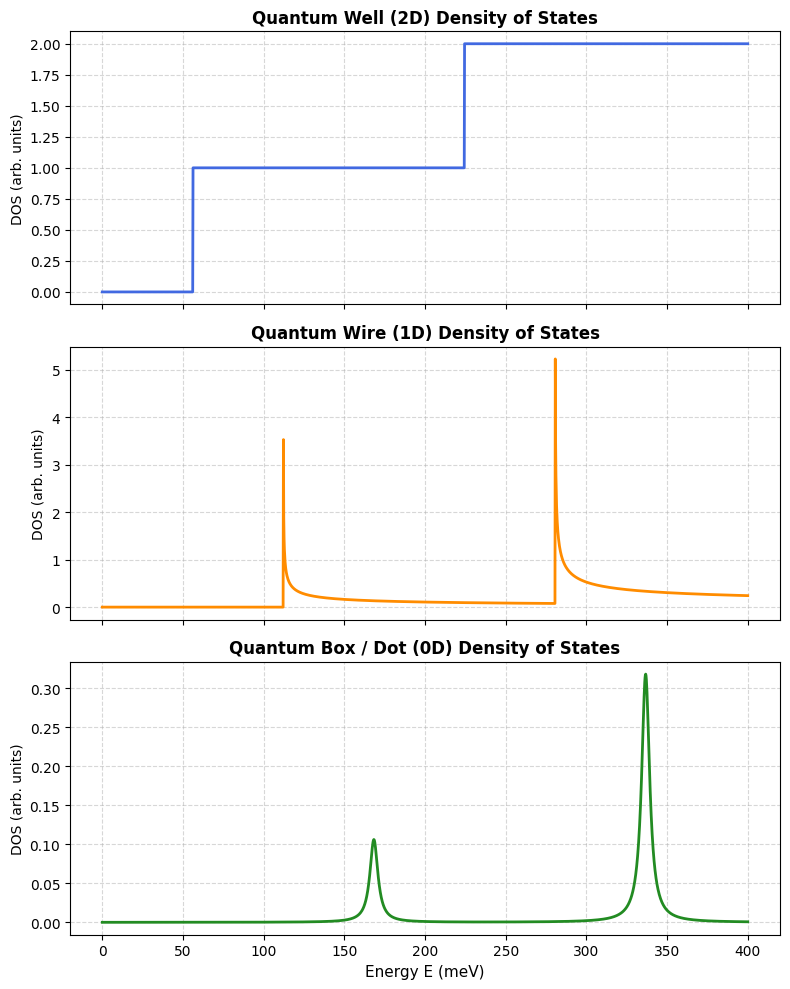

In [51]:
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# 2D Quantum Well Plot
axes[0].plot(E_vals, dos_2d, color='royalblue', lw=2)
axes[0].set_title(
    'Quantum Well (2D) Density of States', fontsize=12, fontweight='bold'
)
axes[0].set_ylabel('DOS (arb. units)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 1D Quantum Wire Plot
axes[1].plot(E_vals, dos_1d, color='darkorange', lw=2)
axes[1].set_title(
    'Quantum Wire (1D) Density of States', fontsize=12, fontweight='bold'
)
axes[1].set_ylabel('DOS (arb. units)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

# 0D Quantum Box Plot
axes[2].plot(E_vals, dos_0d, color='forestgreen', lw=2)
axes[2].set_title(
    'Quantum Box / Dot (0D) Density of States', fontsize=12, fontweight='bold'
)
axes[2].set_xlabel('Energy E (meV)', fontsize=11)
axes[2].set_ylabel('DOS (arb. units)', fontsize=10)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

<>:33: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
<>:33: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_10980\2056649955.py:33: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
  plt.xlabel('Wavevector $k$ ($\AA^{-1}$)')


Fitted c2 coefficient : 56.9040 eV·Å^2
Extracted m*          : 0.0670 m0
True m*               : 0.0670 m0


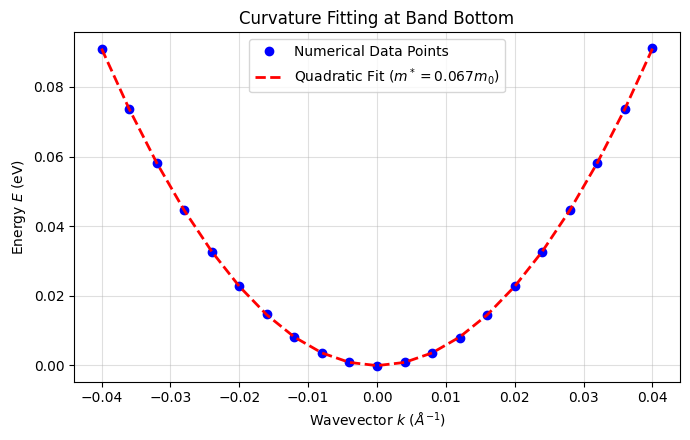

In [52]:
hbar_eV_A = 3.81  # ħ in eV·Å (with m0 scaled out: ħ^2 / (2 m0) = 3.81 eV·Å^2)

# --- 1. Synthetic Band Data (Simulated numerical output near k=0) ---
m_true = 0.067  # True effective mass (GaAs-like)
k_pts = np.linspace(-0.04, 0.04, 21)  # k in Å^-1
E_true = (hbar_eV_A / m_true) * k_pts**2  # E(k) in eV
# Add tiny numerical noise
np.random.seed(42)
E_data = E_true + np.random.normal(0, 1e-4, size=len(k_pts))

# --- 2. Fit quadratic polynomial: E(k) = c2 * k^2 + c0 ---
# Fit against k^2 directly
poly_coeffs = np.polyfit(k_pts**2, E_data, 1)  # returns [c2, c0]
c2 = poly_coeffs[0]

# --- 3. Extract m* ---
m_fitted = hbar_eV_A / c2

print(f'Fitted c2 coefficient : {c2:.4f} eV·Å^2')
print(f'Extracted m*          : {m_fitted:.4f} m0')
print(f'True m*               : {m_true:.4f} m0')

# --- 4. Plotting Verification ---
plt.figure(figsize=(7, 4.5))
plt.plot(k_pts, E_data, 'ob', label='Numerical Data Points')
plt.plot(
    k_pts,
    poly_coeffs[0] * k_pts**2 + poly_coeffs[1],
    'r--',
    lw=2,
    label=f'Quadratic Fit ($m^* = {m_fitted:.3f} m_0$)',
)
plt.xlabel('Wavevector $k$ ($\AA^{-1}$)')
plt.ylabel('Energy $E$ (eV)')
plt.title('Curvature Fitting at Band Bottom')
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()